# 3. Chain occupation dynamics

**Thesis:** Aditya Banerjee, *Linear Anyon Model with Rydberg Atoms*, Universitat de Barcelona (2026). [Read the thesis](https://hdl.handle.net/2445/231684).

**Reading guide:** Section 3.8.2, pp. 25–28; Figures 4–5; phase restriction in Section 4.6. Page numbers below are the printed thesis pages. Equations retain the thesis notation and numbering; an extract from a longer equation is identified as an extract.

**Evidence:** the physics text describes the theoretical model and numerical calculations reported in the thesis. It does not add experimental results or new derivations. Calculation cells come from the original uploaded scripts at commit `22959963191fcbc4d283ec4b272b506ad6dd979b`. Short setup cells only handle notebook execution and display.

Read each explanation, then run its code cell. Source discrepancies and notebook adaptations are labelled explicitly.

**Notebook setup / execution control:** Imports used by the scripts; locate the repository data directory and display plots inline.

In [1]:
%matplotlib inline
from pathlib import Path
from itertools import product
from timeit import default_timer as timer
import numpy as np
from scipy.special import jv
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'scripts').is_dir() and (p / 'data').is_dir())
DATA = ROOT / 'data'

## 1. Chain and effective bond parameters

**Thesis source:** Section 3.6, pp. 20–21; Figure 4, p. 27. Explanations below paraphrase this passage.

Section 3.6 introduces the two quantities
$$A_X\equiv\frac{\Omega_\alpha^2}{X},\qquad
S_j(X)\equiv\Omega_\beta^2\sum_{\ell=-\infty}^{\infty}
\frac{J_\ell^2(\kappa)}{X+\widetilde\nu_j+\ell\omega'}.\tag{41}$$
$X$ is the interaction-energy difference entering a denominator. The diagonal operator in Eq. (42) uses these quantities. For example, its first term is
$$-2A_{C_{01}-2C_{00}}\,|00\rangle\langle00|\qquad\text{[extract from Eq. (42)].}$$
The off-diagonal operator in Eq. (43) connects $01\leftrightarrow10$, $11\leftrightarrow20$, $02\leftrightarrow11$, and $12\leftrightarrow21$.

**Code reading:** `heff2_couplings` calculates the diagonal entries `Eb` and signed exchange coefficients `gs`. Its finite sideband cutoff is `LMAX`. **Code-specific operation:** with `COMPENSATE_11BLOCK=True`, the script replaces the $11$ diagonal by the $20$ diagonal; this is retained exactly as uploaded. The function does not recompute its detunings after this operation.

**Symbols — Table 1, Section 3.3, and Figure 3.**

| Thesis symbol | Meaning | Script name |
|---|---|---|
| $C_{ij}$ | Interaction-shift parameters | `C00`, `C01`, … |
| $\Omega_\alpha,\Omega_\beta$ | Coupling amplitudes | `Om_a`, `Om_b` |
| $\omega'$ | Modulation frequency | `WP` or `wp` |
| $A$ | Modulation amplitude | `A` |
| $\kappa=A/\omega'$ | Modulation index | `kap` or `kappa` |
| $\widetilde\nu_j$ | Floquet detuning at site $j$ | `nu`, `nt0`, `nt1` |
| $J_\ell(\kappa)$ | Bessel function of order $\ell$ | `jv(ells, ...)` |
| $L$, $N$ | Number of sites; total occupation | `L`, `N` |

**Source convention:** the thesis and original scripts label these numerical energies/rates in MHz and use $\hbar=1$ for evolution. Their original labels and numbers are retained here. **Source discrepancy:** the `heff2_states.py` header equates MHz with rad/µs, whereas thesis Appendix B writes $\omega'/(2\pi)=40$ MHz. This notebook reproduces the supplied convention; it does not resolve that frequency conversion or introduce a replacement time variable.

**Code source:** [`heff2_spacetime.py`, lines 54–78](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/heff2_spacetime.py#L54-L78).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [2]:
L = 10
usePBC = False
d = 3

WP = 40.0                 # drive frequency of the main figure [MHz]
PHI_MAIN = 0.0            # statistical angle of the main figure
N_RES = 1                 # locked resonance order
SITE0 = 4                 # where the doublon starts
TMAX = 600.0              # total evolution time
NT = 900                  # time samples

PHI_PANELS = [k * np.pi / 3.0 for k in range(6)]   # 0 .. 5pi/3

# =====================================================================
# 1.  H_eff^(2) COUPLINGS AT omega'   (as in heff2_occupation_maps.py)
# =====================================================================
C00, C01, C11 = 0.0, 20.0, 15.0
C02 = 2.0 * C11
C12, C22 = 45.0, 55.0
Om_a, Om_b = 1.0, 1.0
A = 48.0
COMPENSATE_11BLOCK = True

LMAX = 60
ells = np.arange(-LMAX, LMAX + 1)

**Code source:** [`heff2_spacetime.py`, lines 81–116](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/heff2_spacetime.py#L81-L116).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [3]:
def heff2_couplings(wp):
  kap = A / wp
  nu = 2 * C11 - C02 - N_RES * wp
  Jl = jv(ells, kap)

  def ss(dconst):
    den = dconst + nu + ells * wp
    if np.any(np.abs(den) < 1e-9):
      raise ZeroDivisionError('resonant Stark denominator at wp=%g' % wp)
    return float(np.sum(Jl**2 / den))

  E = {}
  E['00'] = -2 * Om_a**2 / (C01 - 2 * C00)
  E['01'] = (Om_a**2 / (C01 - 2 * C00) - Om_a**2 / (2 * C11 - C01)
             - Om_b**2 * ss(C02 - C01))
  E['02'] = Om_b**2 * ss(C02 - C01) - Om_a**2 / (C12 - C02)
  E['10'] = E['01']
  E['11'] = 2 * Om_a**2 / (2 * C11 - C01) - 2 * Om_b**2 * ss(C12 - 2 * C11)
  E['12'] = (Om_a**2 / (C12 - C02) + Om_b**2 * ss(C12 - 2 * C11)
             - Om_b**2 * ss(2 * C22 - C12))
  E['20'] = E['02']
  E['21'] = E['12']
  E['22'] = 2 * Om_b**2 * ss(2 * C22 - C12)
  if COMPENSATE_11BLOCK:
    E['11'] += E['20'] - E['11']

  g1 = Om_a**2 * (1.0 / (C01 - 2 * C00) - 1.0 / (2 * C11 - C01))
  pref = Om_a * Om_b * (1.0 / (2 * C11 - C01) - 1.0 / (C12 - C02))
  g2 = pref * jv(N_RES, kap)
  g3 = pref * jv(N_RES, kap)
  Sig = (1.0 / (C12 - 2 * C11 + nu + ells * wp)
         - 1.0 / (2 * C22 - C12 + nu + ells * wp))
  g4 = Om_b**2 * float(np.sum(Jl * jv(ells, kap) * Sig))

  Eb = np.array([[E['%d%d' % (a, b)] for b in range(d)] for a in range(d)])
  return Eb, (g1, g2, g3, g4)

## 2. Select the particle-number sector

**Thesis source:** Section 3.8.2, pp. 25–28, and Section 4.6. Explanations below paraphrase this passage.

Section 3.8.2 uses the conservation of Eq. (46). The state
$$|\psi(0)\rangle=|0,0,0,0,2,0,0,0,0,0\rangle\qquad\text{[Section 3.8.2, unnumbered]}$$
has $N=2$ and evolves inside a block of 55 configurations. The reference single excitation starts at the same site. The chain has open ends.

**Source discrepancy:** the original `phases_of` docstring calls the arbitrary-angle pattern physically realized. The thesis explicitly restricts the analysed drive to $\phi\in\{0,\pi\}$ (pp. 28 and 35–37). The copied function's calculation is retained, but its unsupported physical-realization docstring is omitted. Nonzero-angle plots below are target-model calculations, as the thesis states.

**Code source:** [`heff2_spacetime.py`, lines 122–128](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/heff2_spacetime.py#L122-L128).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [4]:
configs = np.array(list(product(range(d), repeat=L)), dtype=np.int8)
Nvec = configs.sum(axis=1).astype(int)
PW = np.array([d**(L - 1 - j) for j in range(L)], dtype=np.int64)
DIMFULL = d**L
BONDS = [(j, j + 1) for j in range(L - 1)]
if usePBC:
  BONDS.append((L - 1, 0))

**Code source:** [`heff2_spacetime.py`, lines 131–157](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/heff2_spacetime.py#L131-L157).

**Notebook changes:** Original function body; remove the docstring whose physical-realization claim conflicts with the thesis. Mode names remain the original script names.

In [5]:
def phases_of(mode, ang, j, alpha=0.0, beta=0.0):

  if mode == 'drive':
    a, b = 0.0, ang
    return -a, b - 2 * a, a - 2 * b, -b
  if mode == 'anyon':
    return 0.0, ang, 0.0, ang
  a_j, a_j1 = (j + 1) * alpha, (j + 2) * alpha
  b_j, b_j1 = (j + 1) * beta, (j + 2) * beta
  return a_j - a_j1, b_j - a_j1, a_j - b_j1, b_j - b_j1

**Code source:** [`heff2_spacetime.py`, lines 160–164](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/heff2_spacetime.py#L160-L164).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [6]:
def sector(N):
  rows = np.where(Nvec == N)[0]
  pos = np.full(DIMFULL, -1, dtype=np.int64)
  pos[rows] = np.arange(len(rows))
  return rows, pos, configs[rows]

**Code source:** [`heff2_spacetime.py`, lines 167–192](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/heff2_spacetime.py#L167-L192).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [7]:
def sector_H(N, Eb, gs, mode, phi, alpha=0.0, beta=0.0):
  """Dense H_eff^(2) restricted to sector N (exact, since [H,N]=0)."""
  rows, pos, cfg = sector(N)
  dim = len(rows)
  g1, g2, g3, g4 = gs
  H = np.zeros((dim, dim), dtype=complex)
  diag = np.zeros(dim)
  for (jL, jR) in BONDS:
    diag += Eb[cfg[:, jL], cfg[:, jR]]
  H[np.arange(dim), np.arange(dim)] = diag
  for jb, (jL, jR) in enumerate(BONDS):
    th = phases_of(mode, phi, jb, alpha, beta)
    for (a, b), (a2, b2), g, t in [((0, 1), (1, 0), g1, th[0]),
                                   ((1, 1), (2, 0), g2, th[1]),
                                   ((0, 2), (1, 1), g3, th[2]),
                                   ((1, 2), (2, 1), g4, th[3])]:
      if g == 0.0:
        continue
      amp = g * np.exp(1j * t)
      sel = np.where((cfg[:, jL] == a) & (cfg[:, jR] == b))[0]
      if sel.size == 0:
        continue
      tgt = pos[rows[sel] + (a2 - a) * PW[jL] + (b2 - b) * PW[jR]]
      H[tgt, sel] += amp
      H[sel, tgt] += np.conj(amp)
  return H, cfg, rows, pos

## 3. Evolve the chain

**Thesis source:** Section 3.8.2, pp. 25–27, using Eq. (48). Explanations below paraphrase this passage.

The block is diagonalized to evaluate the evolution in Eq. (48). The observable plotted in Figures 4–5 is the site occupation $\langle\widehat n_j(t)\rangle$.

**Code reading:** `evolve_density` constructs the normalized initial basis vector, evolves it using the block eigenvectors, and multiplies the resulting configuration probabilities by their site occupations.

**Code source:** [`heff2_spacetime.py`, lines 195–207](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/heff2_spacetime.py#L195-L207).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [8]:
def evolve_density(N, cfgstate, Eb, gs, mode, phi, times, alpha=0.0, beta=0.0):
  """<n_j(t)> for the Fock initial state cfgstate, exactly."""
  H, cfg, rows, pos = sector_H(N, Eb, gs, mode, phi, alpha, beta)
  assert np.allclose(H, H.conj().T, atol=1e-13), 'sector H not Hermitian'
  ev, V = np.linalg.eigh(H)
  i0 = pos[int(np.dot(cfgstate, PW))]
  assert i0 >= 0, 'initial state is not in sector N=%d' % N
  psi0 = np.zeros(len(rows), dtype=complex)
  psi0[i0] = 1.0
  c = V.conj().T @ psi0
  psit = (np.exp(-1j * np.outer(times, ev)) * c) @ V.T     # (Nt, dim)
  p = np.abs(psit)**2
  return p @ cfg.astype(float), ev                          # (Nt, L)

**Code source:** [`heff2_spacetime.py`, lines 213–238](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/heff2_spacetime.py#L213-L238).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [9]:
Eb, gs = heff2_couplings(WP)
g1, g2, g3, g4 = gs
times = np.linspace(0.0, TMAX, NT)

doublon = np.zeros(L, dtype=int)
doublon[SITE0] = 2                       # |0,0,0,0,2,0,0,0>, N = 2
single = np.zeros(L, dtype=int)
single[SITE0] = 1                        # |0,0,0,0,1,0,0,0>, N = 1

dens_main, ev2 = evolve_density(2, doublon, Eb, gs, 'drive', PHI_MAIN, times)
dens_sing, ev1 = evolve_density(1, single, Eb, gs, 'drive', PHI_MAIN, times)
dens_phi = {ph: evolve_density(2, doublon, Eb, gs, 'anyon', ph, times)[0]
            for ph in PHI_PANELS}

print('=' * 78)
print('Spacetime map of <n_j(t)> under H_eff^(2):  L = %d, %s, omega\' = %g MHz'
      % (L, 'PBC' if usePBC else 'OBC', WP))
print('=' * 78)
print('couplings: g1=%+.6f  g2=g3=%+.6f  g4=%+.6f MHz  (kappa = %.4f)'
      % (g1, g2, g4, A / WP))
print('AC-Stark diagonal E_ab [MHz]:')
for a in range(d):
  print('   ' + '  '.join('E_%d%d=%+8.5f' % (a, b, Eb[a, b]) for b in range(d)))
print('initial state |%s>  ->  sector N = %d, dim = %d'
      % (','.join(str(x) for x in doublon), 2, len(sector(2)[0])))
print('evolution: exact, %d time samples on [0, %g]' % (NT, TMAX))

Spacetime map of <n_j(t)> under H_eff^(2):  L = 10, OBC, omega' = 40 MHz
couplings: g1=-0.050000  g2=g3=+0.016610  g4=-0.010120 MHz  (kappa = 1.2000)
AC-Stark diagonal E_ab [MHz]:
   E_00=-0.10000  E_01=-0.05655  E_02=-0.06012
   E_10=-0.05655  E_11=-0.06012  E_12=+0.05655
   E_20=-0.06012  E_21=+0.05655  E_22=+0.01012
initial state |0,0,0,0,2,0,0,0,0,0>  ->  sector N = 2, dim = 55
evolution: exact, 900 time samples on [0, 600]


## 4. Plot the single excitation and doublon

**Thesis source:** Section 3.8.2, pp. 26–27, Figure 4. Explanations below paraphrase this passage.

Figure 4 compares the single-excitation reference with the doublon released at site 4. The thesis describes the slower doublon spreading and identifies the zero-angle left–right imbalance as an effect of the off-centre initial site. These are stroboscopic occupations.

**Code source:** [`heff2_spacetime.py`, lines 325–388](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/heff2_spacetime.py#L325-L388).

**Notebook changes:** Original figure code; inline display replaces file export.

Spacetime map of $\langle\hat n_j(t)\rangle$ under $H_{\mathrm{eff}}^{(2)}$:  $L=10$, OBC, $\omega'=40$ MHz, $\theta=0.00\pi$ ($\phi=-\theta$)
$A_1$: $|01\rangle\!\to\!|10\rangle$ exchange   $A_2$: $|11\rangle\!\to\!|20\rangle$ Floquet-assisted   $A_3$: $|02\rangle\!\to\!|11\rangle$ Floquet-assisted   $A_4$: $|12\rangle\!\to\!|21\rangle$ cross-site
$A_1=0.0500$,  $A_2=A_3=0.0166$,  $A_4=0.0101$ MHz   (signed: $-0.0500$, $+0.0166$, $-0.0101$)


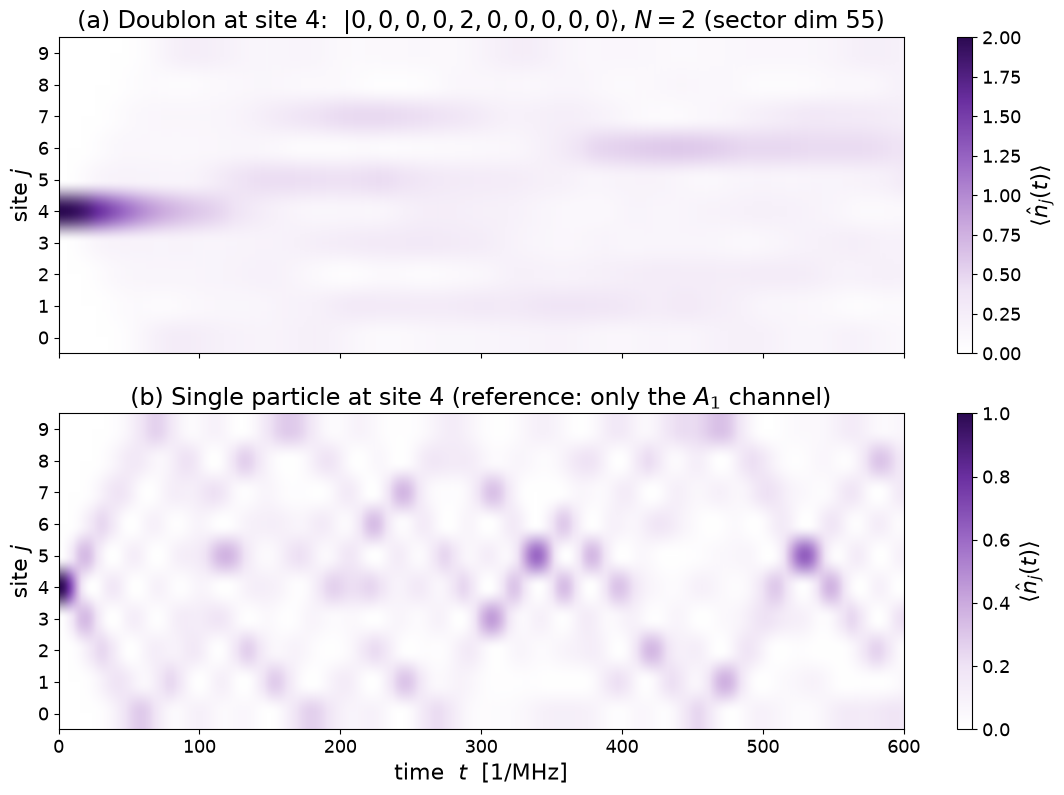

In [10]:
import matplotlib
# Inline backend selected in notebook setup.
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 15, 'axes.titlesize': 17, 'axes.labelsize': 16,
                     'xtick.labelsize': 13, 'ytick.labelsize': 13,
                     'legend.fontsize': 14, 'figure.titlesize': 17})
from matplotlib.colors import LinearSegmentedColormap

# Density colour scale: pure white at <n_j> = 0 rising to deep violet at the
# maximum, so empty sites read as blank page rather than as a filled dark
# background and the occupied structure is what carries ink.
CMAP_DENS = LinearSegmentedColormap.from_list(
    'white_violet', ['#ffffff', '#efe3f5', '#cbaade', '#9c6ac6', '#6a2fa0',
                     '#2c0a52'])

# The four second-order coupling channels.  Labelled A_1..A_4 to match the
# thesis notation of eq:ampconditions, where A_i are defined as the MAGNITUDES
# |.| of these amplitudes; the signed values are printed in GSIGNED below.
GLABEL = (r'$A_1$: $|01\rangle\!\to\!|10\rangle$ exchange   '
          r'$A_2$: $|11\rangle\!\to\!|20\rangle$ Floquet-assisted   '
          r'$A_3$: $|02\rangle\!\to\!|11\rangle$ Floquet-assisted   '
          r'$A_4$: $|12\rangle\!\to\!|21\rangle$ cross-site')

sites = np.arange(L)
EXT = [times[0], times[-1], -0.5, L - 0.5]

# ---------------------------------------------------------------- fig 1
fig, axs = plt.subplots(2, 1, figsize=(11.5, 8.2), sharex=True,
                        gridspec_kw={'height_ratios': [1, 1]})

ax = axs[0]
im = ax.imshow(dens_main.T, origin='lower', aspect='auto', extent=EXT,
               cmap=CMAP_DENS, vmin=0.0, vmax=2.0)
fig.colorbar(im, ax=ax, label=r'$\langle \hat n_j(t)\rangle$')
ax.set_yticks(sites)
ax.set_ylabel('site $j$')
KET = ','.join(str(x) for x in doublon)      # built from the state, not hardcoded
ax.set_title(r'(a) Doublon at site %d:  $|%s\rangle$, $N=2$ (sector dim %d)'
             % (SITE0, KET, len(sector(2)[0])))

ax = axs[1]
im = ax.imshow(dens_sing.T, origin='lower', aspect='auto', extent=EXT,
               cmap=CMAP_DENS, vmin=0.0, vmax=1.0)
fig.colorbar(im, ax=ax, label=r'$\langle \hat n_j(t)\rangle$')
ax.set_yticks(sites)
ax.set_ylabel('site $j$')
ax.set_xlabel(r'time  $t$  [1/MHz]')
ax.set_title(r'(b) Single particle at site %d (reference: only the $A_1$ '
             r'channel)' % SITE0)

GVALS = (r'$A_1=%.4f$,  $A_2=A_3=%.4f$,  $A_4=%.4f$ MHz'
         '   ' r'(signed: $%+.4f$, $%+.4f$, $%+.4f$)'
         % (abs(g1), abs(g2), abs(g4), g1, g2, g4))
_head = (r'Spacetime map of $\langle\hat n_j(t)\rangle$ under '
         r"$H_{\mathrm{eff}}^{(2)}$:  $L=%d$, %s, $\omega'=%g$ MHz, "
         r'$\theta=%.2f\pi$ ($\phi=-\theta$)'
         % (L, 'PBC' if usePBC else 'OBC', WP, PHI_MAIN / np.pi))
# The run header (_head, GLABEL, GVALS) is deliberately NOT drawn: at thesis
# scale it is illegible, and the same information is in the caption and in the
# parameter table of Sec. 2.2.  It is printed to stdout instead.
print(_head); print(GLABEL); print(GVALS)
fig.tight_layout()
plt.show()

## 5. Target-model phase comparison

**Thesis source:** Section 3.8.2, pp. 27–28, Eq. (56), Figure 5. Explanations below paraphrase this passage.

The thesis asks how the densities would change if the statistical phase could be engineered. It gives the relation
$$\langle\widehat n_j(t)\rangle_{-\theta}=\langle\widehat n_j(-t)\rangle_{\theta}.\tag{56}$$
Figure 5 therefore samples six angles around the full circle. The thesis explicitly presents this as a target-model comparison, subject to the drive restriction in Section 4.6.

**Source discrepancy:** the supplied script calculates `dens_phi` using `mode='anyon'` at positive `ph`, although its original plot header calls this the drive angle $\theta$ with $\phi=-\theta$. The notebook preserves the calculation and labels these panels by the target statistical angle $\phi$ actually passed to that function. The arrays should not be described as an exact regeneration of the thesis's signed-$\theta$ panels without resolving this convention.

**Code source:** [`heff2_spacetime.py`, lines 391–412](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/heff2_spacetime.py#L391-L412).

**Notebook changes:** Retain original six target-phase calculations. Correct the displayed symbol to phi and omit the inconsistent drive-angle header; inline display replaces file export.

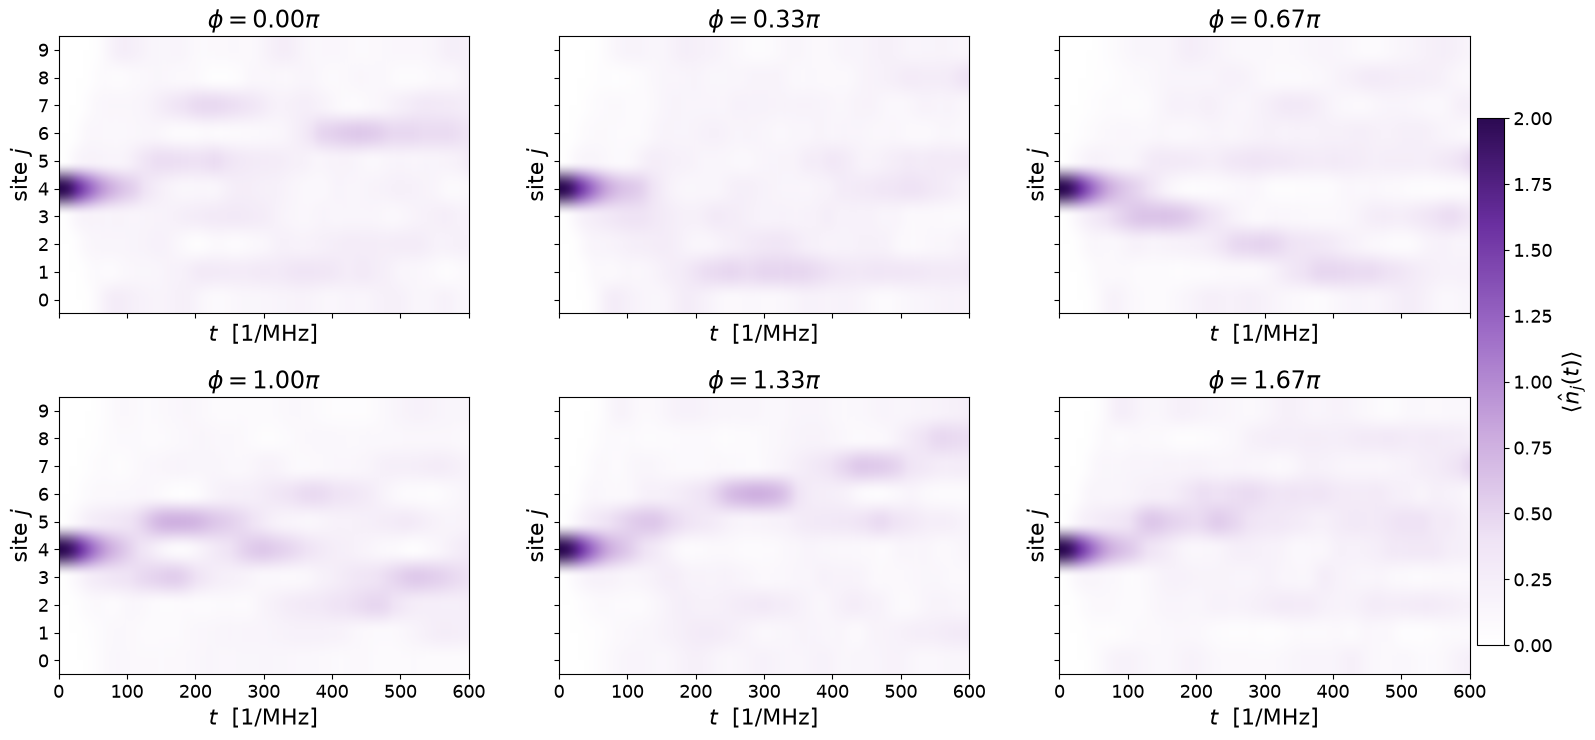

In [11]:
n = len(PHI_PANELS)
fig, axs = plt.subplots(2, 3, figsize=(17, 7.6), sharex=True, sharey=True)
axs = axs.ravel()
for ax, ph in zip(axs, PHI_PANELS):
  im = ax.imshow(dens_phi[ph].T, origin='lower', aspect='auto', extent=EXT,
                 cmap=CMAP_DENS, vmin=0.0, vmax=2.0)
  ax.set_yticks(sites)
  ax.set_title(r'$\phi=%.2f\pi$' % (ph / np.pi))
  ax.set_xlabel(r'$t$  [1/MHz]')
  ax.set_ylabel('site $j$')
fig.colorbar(im, ax=axs[:n].tolist(), label=r'$\langle \hat n_j(t)\rangle$',
             fraction=0.02)


fig.subplots_adjust(top=0.95, hspace=0.30, wspace=0.22,
                    left=0.05, right=0.88, bottom=0.11)
plt.show()

## Source and reproduction record

The original scripts and saved data are unchanged. See [SOURCE_MAP.md](SOURCE_MAP.md) for the thesis-to-code map and [VALIDATION.md](VALIDATION.md) for the checks performed on this revision.